# 19 - LSTM with a larger training sample

Is the LSTM's low score caused by too little training data? Same protocol as notebook 16, but trained on 100,000 evenly spaced normal sequences from the first 60% instead of 20,000.

In [1]:
import sys
from pathlib import Path

import pandas as pd
import torch

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.evaluation.cross_system import chosen_rows
from src.models.lstm import DeepLogLSTM, sweep_k
from src.models.unsupervised import time_split_val

DOCS, PROCESSED, MODELS = ROOT / "docs", ROOT / "data" / "processed", ROOT / "models"
H, KS = 10, [1, 2, 3, 5, 9, 12]  # as in notebook 16
LABELLED = {"HDFS": ("hdfs", "order"), "BGL": ("bgl", "window")}

## Training

Trained with `scripts/train_lstm_large.py` (CPU, run in the background): same model (embedding 32, 2 layers of 64, h = 10), Adam lr 0.001, batch 512, up to 30 epochs, early stopping after 3 epochs without improvement on 10% of the training sequences, seed 42. Saved as `models/<dataset>_lstm_large100k.pt`.

In [2]:
# weights_only=False: the files also hold the training history (a DataFrame); they are our own files
saved = {name: torch.load(MODELS / f"{prefix}_lstm_large100k.pt", weights_only=False) for name, (prefix, _) in LABELLED.items()}
pd.DataFrame([{"dataset": name, "train sequences": s["train_sequences"], "epochs": s["epochs"],
               "best epoch (weights kept)": int(s["history"]["val_loss"].idxmin()) + 1,
               "training time (min)": s["train_seconds"] / 60, "event types seen": len(s["train_events"]),
               "event types": len(s["vocab"])} for name, s in saved.items()]) \
    .style.format({"train sequences": "{:,}", "training time (min)": "{:.1f}"}).hide(axis="index")

dataset,train sequences,epochs,best epoch (weights kept),training time (min),event types seen,event types
HDFS,"100,000",15,12,26.4,19,45
BGL,"100,000",16,13,27.5,184,391


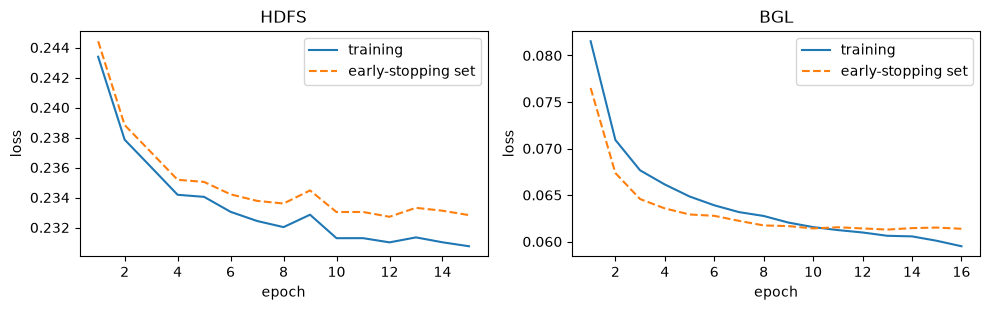

In [3]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, (name, s) in zip(axes, saved.items()):
    history = s["history"]
    ax.plot(history["epoch"], history["train_loss"], label="training")
    ax.plot(history["epoch"], history["val_loss"], label="early-stopping set", linestyle="--")
    ax.set(title=name, xlabel="epoch", ylabel="loss")
    ax.legend()
plt.tight_layout()

## Choose k on validation, test once

Same rule as before: a sequence is flagged if an observed event is outside the top k predictions, or if it has an event never seen in the training sequences.

In [4]:
val_rows, test_rows = [], []
for name, (prefix, order_col) in LABELLED.items():
    s = saved[name]
    model = DeepLogLSTM(num_events=len(s["vocab"]), **{k: v for k, v in s["config"].items() if k != "h"})
    model.load_state_dict(s["state_dict"])
    model.eval()
    _, val, test = time_split_val(pd.read_parquet(PROCESSED / f"{prefix}_sequences.parquet"), order_col=order_col)
    known = set(s["train_events"])
    v, *_ = sweep_k(model, val["EventSequence"].tolist(), s["vocab"], known, KS, val["Label"].to_numpy(), H)
    t, *_ = sweep_k(model, test["EventSequence"].tolist(), s["vocab"], known, KS, test["Label"].to_numpy(), H)
    val_rows.append(v.assign(dataset=name, model="LSTM"))
    test_rows.append(t.assign(dataset=name, model="LSTM"))

val_table, test_table = pd.concat(val_rows, ignore_index=True), pd.concat(test_rows, ignore_index=True)
val_table.pivot_table(index="dataset", columns="k", values="f1", sort=False).round(3)

k,1,2,3,5,9,12
dataset,,,,,,
HDFS,0.090,0.385,0.450,0.506,0.433,0.417
BGL,0.241,0.258,0.271,0.279,0.289,0.293


Validation F1 by k (above). Test results at the chosen k:

In [5]:
chosen = chosen_rows(val_table, test_table, "k")
results = pd.DataFrame({
    "dataset": chosen["dataset"],
    "train_sequences": chosen["dataset"].map(lambda d: saved[d]["train_sequences"]),
    "chosen_k": chosen["k"],
    **{c: chosen[c] for c in ["precision", "recall", "f1", "false_alarm_rate"]},
    "epochs": chosen["dataset"].map(lambda d: saved[d]["epochs"]),
})
results.round(4).to_csv(DOCS / "lstm_large_results.csv", index=False)
results.style.format({"train_sequences": "{:,}"} | {c: "{:.4f}" for c in ["precision", "recall", "f1", "false_alarm_rate"]}).hide(axis="index")

dataset,train_sequences,chosen_k,precision,recall,f1,false_alarm_rate,epochs
HDFS,"100,000",5,0.8582,0.4389,0.5808,0.0016,15
BGL,"100,000",12,0.0984,0.9925,0.1790,0.7331,16


## Compared with 20,000 sequences

The 20,000-sequence rows are the notebook 16 results (`docs/cross_system_results.csv`).

In [6]:
old = pd.read_csv(DOCS / "cross_system_results.csv")
old = old[(old["model"] == "LSTM") & old["dataset"].isin(LABELLED) & (old["chosen on"] == old["dataset"])]
compare = pd.concat([
    old.assign(train_sequences=20_000, chosen_k=old["setting"].str.split().str[-1].astype(int))[
        ["dataset", "train_sequences", "chosen_k", "precision", "recall", "f1", "false_alarm_rate"]],
    results.drop(columns="epochs"),
]).sort_values(["dataset", "train_sequences"], key=lambda c: c.map({"HDFS": 0, "BGL": 1}) if c.name == "dataset" else c)
compare.style.format({"train_sequences": "{:,}"} | {c: "{:.4f}" for c in ["precision", "recall", "f1", "false_alarm_rate"]}).hide(axis="index")

dataset,train_sequences,chosen_k,precision,recall,f1,false_alarm_rate
HDFS,"20,000",5,0.8017,0.4300,0.5598,0.0023
HDFS,"100,000",5,0.8582,0.4389,0.5808,0.0016
BGL,"20,000",12,0.0974,0.9925,0.1774,0.7410
BGL,"100,000",12,0.0984,0.9925,0.1790,0.7331


## Findings

- **HDFS: a small gain.** F1 rises from 0.560 to 0.581, mostly from precision (0.80 to 0.86); recall stays at about 0.44. Five times more data doesn't fix the low recall.
- **BGL: no real change.** F1 0.177 to 0.179, recall 0.99, still about 73% false alarms. The model now sees 184 of 391 event types instead of 130, but the test period still looks new to it (drift).
- **Conclusion:** too little training data is not the main reason for the LSTM's low score. On HDFS the limit is more likely the model and detection rule; on BGL, the change in the data over time. The chosen k is the same as before (5 and 12).